In [1]:
# 실습 준비 - 패키지 설치·폰트
#  새로 설치하는 것은 하나입니다 — 교안의 수를 계산한 버전에 맞춰 고정합니다(버전을 바꾸면 문서 비율이 소수 둘째 자리에서 달라질 수 있습니다).
#    kiwipiepy 0.23.1 : 한국어 형태소 분석기 Kiwi
#  numpy · pandas · scikit-learn · matplotlib 은 Colab 기본 버전을 그대로 씁니다. 설치는 Colab 에서만 합니다.
import os, sys, math, time
import subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kiwipiepy==0.23.1"], check=False)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import warnings; warnings.filterwarnings("ignore")

# 한글 폰트 — Colab 이면 나눔고딕을 설치한 뒤 그 ttf 를 폰트 목록에 **직접** 등록한다.
#  설치는 디스크에 파일만 만든다. 이미 떠 있는 폰트 목록은 그 사실을 모르므로 addfont 로
#  등록해야 이름이 보인다(등록하지 않으면 DejaVu Sans 로 밀려 한글이 전부 □ 로 나온다).
import glob, shutil
if IN_COLAB and shutil.which("apt-get"):
    subprocess.run(["apt-get", "-y", "-qq", "install", "fonts-nanum"], check=False)
for _p in glob.glob("/usr/share/fonts/truetype/nanum/Nanum*.ttf"):   # 설치 여부와 무관하게 한 번
    try: fm.fontManager.addfont(_p)
    except Exception: pass
try: fm._get_font.cache_clear()
except Exception: pass
installed = {f.name for f in fm.fontManager.ttflist}
FONT = next((n for n in ["Pretendard", "Apple SD Gothic Neo", "NanumGothic"] if n in installed), "DejaVu Sans")
plt.rcParams["font.family"] = FONT
plt.rcParams["axes.unicode_minus"] = FONT in {"Pretendard", "DejaVu Sans"}   # 나머지 폰트에는 U+2212 가 없다
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}   # 그림마다 폭이 깎이지 않게
plt.rcParams["figure.dpi"] = plt.rcParams["savefig.dpi"] = 150       # 폭 FIG_W x 150dpi = 1500px 고정
plt.rcParams["figure.autolayout"] = True
plt.rcParams.update({"font.size": 11, "axes.titlesize": 15, "axes.labelsize": 12,
                     "legend.fontsize": 11, "figure.titlesize": 17, "font.weight": "regular",
                     "text.color": "black", "axes.labelcolor": "black", "axes.titlecolor": "black",
                     "axes.edgecolor": "#757575", "xtick.color": "#757575", "ytick.color": "#757575",
                     "xtick.labelcolor": "black", "ytick.labelcolor": "black",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False})

# 이 실습의 그림 전체가 함께 쓰는 색 — 기준선=남색, 관측=파랑, 강조=하늘색, 문맥=회색
COL = {"남색": "#051C2C", "파랑": "#2251FF", "하늘색": "#00A9F4",
       "회색": "#757575", "연회색": "#B3B3B3"}
FIG_W = 10.0     # 캔버스 폭은 이 실습의 그림 모두 이 값으로 고정하고 높이만 그림마다 조절한다

try:
    import kiwipiepy
    _kiwi_ver = kiwipiepy.__version__
except ImportError:
    _kiwi_ver = "없음"
print("사용 폰트:", FONT, "| 색 팔레트 준비 완료 | kiwipiepy", _kiwi_ver)
if _kiwi_ver != "0.23.1":
    print("참고 — 교안의 수는 kiwipiepy 0.23.1 에서 계산했습니다. 지금 버전에서는 문서 비율이 소수 둘째 자리쯤 다를 수 있습니다.")

사용 폰트: DejaVu Sans | 색 팔레트 준비 완료 | kiwipiepy 0.24.0
참고 — 교안의 수는 kiwipiepy 0.23.1 에서 계산했습니다. 지금 버전에서는 문서 비율이 소수 둘째 자리쯤 다를 수 있습니다.


In [3]:

# ===== 한글 폰트 설정 =====
font_path = "C:/Windows/Fonts/malgun.ttf"
fm.fontManager.addfont(font_path)
plt.rcParams["font.family"] = fm.FontProperties(fname=font_path).get_name()
plt.rcParams["axes.unicode_minus"] = False

표 1 · 리뷰 4만 건에서 |z| 가 1.96 을 넘은 단어 수 (개)
  실제 비교(별점 1·2점 대 4·5점)   1,236  (어휘 3,879개)
  라벨을 다시 배정한 비교 20번     평균 113.8  (96～134)
표 2 · 라벨을 다시 배정한 비교 20번에서 번마다 가장 큰 |z|
  20번의 범위                       2.94～3.90
  실제 비교에서 3.90 을 넘은 단어  444개
표 3 · 두 연령대 민원이 많은 품목 5개 (건)
  헬스장 : 20대 208 · 60대 이상 11
  이동전화서비스 : 20대 81 · 60대 이상 93
  기타미분류서비스 : 20대 41 · 60대 이상 106
  기타미분류물품 : 20대 43 · 60대 이상 77
  국외여행 : 20대 28 · 60대 이상 87
  두 연령대 전체 : 20대 2,175 · 60대 이상 2,446


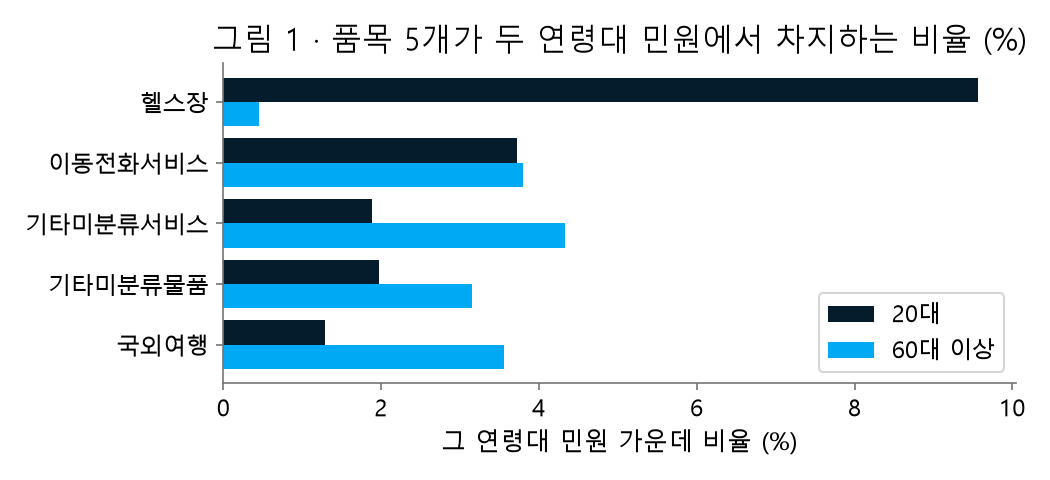

표 4 · 예약과 중도를 쓴 민원 수 (건)
  예약 전체 : 20대 58 · 60대 이상 11 (전체 비교의 z 5.30)
  예약 품목 5개 안 : 20대 4 · 60대 이상 3
  중도 전체 : 20대 91 · 60대 이상 35 (전체 비교의 z 5.18)
  중도 품목 5개 안 : 20대 41 · 60대 이상 5
표 5 · 헬스장 품목 안에서 다시 비교한 중도
  20대       40/208건  문서 비율 19.2%
  60대 이상  2/11건  문서 비율 18.2%
  품목 안 z  2.46  (전체 비교의 z 5.18)


In [4]:
# 오늘의 준비 — 읽고 실행만 합니다
# 리뷰 4만 건과 민원 2만 건으로 표 1～5 와 그림 1 을 만듭니다. 처음 한 번은 원자료를 받느라 1분 안팎 걸립니다
import os, re, time, hashlib, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from kiwipiepy import Kiwi

os.environ.setdefault("KIWI_ARCH_TYPE", "balanced")   # CPU 종류(Mac·Colab)와 상관없이 형태소 분석 결과를 같게

# 원자료 — 원 출처 URL · 파일 이름 · SHA-256(2026-09-24 확인) · 데이터 페이지
RAW_FILES = {
    "reviews": ("https://raw.githubusercontent.com/bab2min/corpus/master/sentiment/naver_shopping.txt",
                "naver_shopping.txt",
                "dc4d1aca0a148671cbe80bcb81962eee297370acab42be93c1617ce9336479c0",
                "https://github.com/bab2min/corpus/tree/master/sentiment"),
    "complaints": ("https://www.data.go.kr/cmm/cmm/fileDownload.do?"
                   "atchFileId=FILE_000000002610054&fileDetailSn=1&insertDataPrcus=N",
                   "kftc_complaints_1.csv",
                   "50c098fea2ec1d05191d07c45cd0f75b4d0ac3b5e5ac36910fe40f2aab699ebe",
                   "https://www.data.go.kr/data/15098314/fileData.do"),
}
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"   # 과정 복제본 — 원 출처와 같은 바이트, 먼저 받는 곳


def data_dir():
    # 자료 폴더: 환경변수 NLP_DATA_DIR 이 있으면 그 폴더, 없으면 ./nlp_data
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    # 자료 폴더 → cache/ → raw/ 순서로 찾아 처음 나온 경로, 없으면 None
    for sub in ("", "cache", "raw"):
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def fetch_one(url, name):
    # url 에서 받아 자료 폴더/cache/ 에 두고 경로를 반환함 — 실패하면 세 번까지 다시 시도하고, 끝내 못 받으면 None
    path = os.path.join(data_dir(), "cache", name)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    for i in range(3):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            os.replace(path + ".part", path)
            return path
        except Exception as e:
            print(f"받기 실패 {i + 1}/3: {e}")
            time.sleep(2 * (i + 1))
    return None


def fetch_raw(name):
    # 원자료 경로: 로컬을 먼저 보고, 없으면 과정 복제본(MIRROR_URL) → 원 출처 URL 순서로 받음
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = fetch_one(f"{MIRROR_URL}/{fname}", fname)
        if path is not None and sha256_of(path) != sha:   # 복제본이 다르면 버리고 원 출처로
            os.remove(path)
            path = None
    if path is None:
        path = fetch_one(url, fname)
    if path is None:
        raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 교안과 다를 수 있습니다(데이터 페이지: {page})")
    return path


def clean_review(text):
    # 리뷰 문자열 정리 — 자음 넷 이상의 자모 나열은 지우고, 같은 자모 반복은 두 글자로 줄인다
    text = re.sub(r"[ㄱ-ㅣㆍ]{4,}", lambda m: "" if len(set(re.findall(r"[ㄱ-ㅎ]", m.group()))) >= 4 else m.group(), text)
    text = re.sub(r"([ㄱ-ㅎㅏ-ㅣ])\1{2,}", r"\1\1", text)
    return re.sub(r"\s{2,}", " ", text).strip()


TEST_INPUT_RE = re.compile(   # 민원 파일의 시험 입력 행
    r"(?i)^\s*(?:test|테스트)\s*(?:입니다)?\s*\.?\s*$"
    r"|IN-TEST"
    r"|(?:인바운드|아웃바운드|녹취|수화기).*테스트|테스트.*(?:인바운드|아웃바운드|녹취|수화기)"
    r"|^\s*자동차\s*(?:상담\s*)?테스트"
    r"|^\s*\d{8}\s*[-_ ].*테스트"
    r"|테스트\s*데이터|상담\s*(?:전화\s*)?테스트|전화\s*테스트|헬프데스크\s*시험|^\s*일반\s*테스트")
EMPTY_TITLE_RE = re.compile(r"^[^가-힣A-Za-z]*$")   # 한글 음절도 로마자도 없는 제목
PHONE_RE = re.compile(r"(?<!\d)(?:01[016789]|0\d{1,2})[-.)\s]{0,2}\d{3,4}[-.\s]\d{4}(?!\d)")   # 전화번호 형태


def wlo(sets_a, sets_b, alpha0=1000.0, min_df=5):
    """가중 로그 오즈(문서 단위) — 이론 「3. 가중 로그 오즈」의 식. z > 0 이면 a 쪽, z < 0 이면 b 쪽 특징 단어"""
    ca = pd.Series([w for s in sets_a for w in set(s)]).value_counts()      # 단어마다 그 단어를 쓴 문서 수
    cb = pd.Series([w for s in sets_b for w in set(s)]).value_counts()
    t = pd.DataFrame({"ya": ca, "yb": cb}).fillna(0).astype(int).rename_axis("w").reset_index()
    t = t[t.ya + t.yb >= min_df].sort_values("w").reset_index(drop=True)      # 어휘: 두 집단 합쳐 문서 min_df 건 이상
    na, nb, tot = len(sets_a), len(sets_b), t.ya + t.yb
    t["a_w"] = alpha0 * tot / tot.sum()                                        # 두 집단 문서 합에 비례하는 사전 문서 수
    t["delta"] = (np.log((t.ya + t.a_w) / (na + alpha0 - t.ya - t.a_w))
                  - np.log((t.yb + t.a_w) / (nb + alpha0 - t.yb - t.a_w)))
    t["z"] = t.delta / np.sqrt(1 / (t.ya + t.a_w) + 1 / (t.yb + t.a_w))
    return t


KIWI = Kiwi(num_workers=2)

# 리뷰 4만 건(시드 0) → 리뷰마다 명사 + 용언 집합 → 별점 1·2점 대 4·5점의 가중 로그 오즈
rows = [ln.split("\t", 1) for ln in open(fetch_raw("reviews"), encoding="utf-8").read().split("\n") if ln]
reviews = pd.DataFrame(rows, columns=["별점", "본문"]).sample(n=40000, random_state=0)
review_sets = []
for toks in KIWI.tokenize(reviews["본문"].map(clean_review).tolist()):
    review_sets.append({t.form + ("다" if t.tag.split("-")[0] in ("VV", "VA") else "") for t in toks
                        if t.tag.split("-")[0] in ("NNG", "NNP", "VV", "VA")})
is_low = reviews["별점"].astype(int).isin([1, 2]).to_numpy()
real = wlo([s for s, m in zip(review_sets, is_low) if m], [s for s, m in zip(review_sets, is_low) if not m])
n_real = int((real.z.abs() > 1.96).sum())

# 별점 라벨을 무작위로 다시 배정한 비교 20번 — 두 집단 크기는 그대로, 시드 0 으로 고정
rng = np.random.default_rng(0)
perm_cnt, perm_top = [], []
for _ in range(20):
    lab = rng.permutation(is_low)
    t = wlo([s for s, m in zip(review_sets, lab) if m], [s for s, m in zip(review_sets, lab) if not m])
    perm_cnt.append(int((t.z.abs() > 1.96).sum()))
    perm_top.append(float(t.z.abs().max()))
perm_mean, perm_max = float(np.mean(perm_cnt)), max(perm_top)
n_above = int((real.z.abs() > perm_max).sum())

print("표 1 · 리뷰 4만 건에서 |z| 가 1.96 을 넘은 단어 수 (개)")
print(f"  실제 비교(별점 1·2점 대 4·5점)   {n_real:,}  (어휘 {len(real):,}개)")
print(f"  라벨을 다시 배정한 비교 20번     평균 {perm_mean:.1f}  ({min(perm_cnt)}～{max(perm_cnt)})")
print("표 2 · 라벨을 다시 배정한 비교 20번에서 번마다 가장 큰 |z|")
print(f"  20번의 범위                       {min(perm_top):.2f}～{perm_max:.2f}")
print(f"  실제 비교에서 {perm_max:.2f} 을 넘은 단어  {n_above:,}개")

# 민원 2만 건(시드 0) → 제목마다 명사 집합 → 20대와 60대 이상
raw = pd.read_csv(fetch_raw("complaints"), encoding="cp949", dtype=str)
raw = raw.rename(columns=lambda c: c.split("(")[0].strip())
title = raw["사건제목"].fillna("").str.strip()
is_test = title.str.contains(TEST_INPUT_RE)
keep = ~is_test & ~(title.str.match(EMPTY_TITLE_RE) & ~is_test)
cmp20 = raw[keep].copy()
cmp20["사건제목"] = title[keep].map(lambda x: PHONE_RE.sub("[전화번호]", x))
cmp20 = cmp20.reset_index(drop=True).sample(n=20000, random_state=0)
noun_sets = [{t.form for t in toks if t.tag in ("NNG", "NNP")} for toks in KIWI.tokenize(cmp20["사건제목"].tolist())]
age = cmp20["연령대명"].to_numpy()
is20 = age == "20 - 29세"
is60p = np.isin(age, ["60 - 64세", "65 - 69세", "70 - 79세", "80세이상"])
items = cmp20["품목명"].fillna("미상").to_numpy()
top5 = pd.Series(items[is20 | is60p]).value_counts().head(5).index.tolist()   # 두 연령대를 합쳐 민원이 많은 품목 5개

print("표 3 · 두 연령대 민원이 많은 품목 5개 (건)")
for it in top5:
    print(f"  {it} : 20대 {int((is20 & (items == it)).sum())} · 60대 이상 {int((is60p & (items == it)).sum())}")
print(f"  두 연령대 전체 : 20대 {int(is20.sum()):,} · 60대 이상 {int(is60p.sum()):,}")

fig, ax = plt.subplots(figsize=(FIG_W * 0.7, 3.2))
y = np.arange(len(top5))
ax.barh(y - 0.2, [100 * (is20 & (items == it)).sum() / is20.sum() for it in top5], 0.4, label="20대", color=COL["남색"])
ax.barh(y + 0.2, [100 * (is60p & (items == it)).sum() / is60p.sum() for it in top5], 0.4, label="60대 이상", color=COL["하늘색"])
ax.set_yticks(y, top5)
ax.invert_yaxis()
ax.set_xlabel("그 연령대 민원 가운데 비율 (%)")
ax.set_title("그림 1 · 품목 5개가 두 연령대 민원에서 차지하는 비율 (%)")
ax.legend()
plt.show()

# 20대 쪽 z 가 기준을 넘은 두 단어 — 전체 비교와 품목 5개 안의 문서 수
full = wlo([s for s, m in zip(noun_sets, is20) if m], [s for s, m in zip(noun_sets, is60p) if m]).set_index("w")
in5 = np.isin(items, top5)
word_rows = {}
for w in ["예약", "중도"]:
    has = np.array([w in s for s in noun_sets])
    word_rows[w] = {"all_20": int((is20 & has).sum()), "all_60": int((is60p & has).sum()), "z": float(full.z[w]),
                    "in5_20": int((is20 & has & in5).sum()), "in5_60": int((is60p & has & in5).sum())}
print("표 4 · 예약과 중도를 쓴 민원 수 (건)")
for w, r in word_rows.items():
    print(f"  {w} 전체 : 20대 {r['all_20']} · 60대 이상 {r['all_60']} (전체 비교의 z {r['z']:.2f})")
    print(f"  {w} 품목 5개 안 : 20대 {r['in5_20']} · 60대 이상 {r['in5_60']}")

# 헬스장 품목 안에서 다시 계산한 「중도」
gym20, gym60 = is20 & (items == "헬스장"), is60p & (items == "헬스장")
gym = wlo([s for s, m in zip(noun_sets, gym20) if m], [s for s, m in zip(noun_sets, gym60) if m]).set_index("w")
has = np.array(["중도" in s for s in noun_sets])
gym_rate20, gym_rate60 = (gym20 & has).sum() / gym20.sum(), (gym60 & has).sum() / gym60.sum()
gym_z = float(gym.z["중도"])
print("표 5 · 헬스장 품목 안에서 다시 비교한 중도")
print(f"  20대       {int((gym20 & has).sum())}/{int(gym20.sum())}건  문서 비율 {100 * gym_rate20:.1f}%")
print(f"  60대 이상  {int((gym60 & has).sum())}/{int(gym60.sum())}건  문서 비율 {100 * gym_rate60:.1f}%")
print(f"  품목 안 z  {gym_z:.2f}  (전체 비교의 z {word_rows['중도']['z']:.2f})")

별점 낮은 쪽 특징 단어로 먼저 볼 단어
예를 들어 리뷰를 별점 1·2점과 4·5점으로 2만 건씩 나눴고, 두 단어의 문서 비율이 아래와 같다고 합시다.
단어 A 별점 1·2점 40% · 4·5점 38%
단어 B 별점 1·2점 3% · 4·5점 0.5%

B 단어 B: 두 집단의 비율 차이가 크고 건수도 많다

특징 단어는 한 집단이 많이 쓰는 단어가 아니라 두 집단의 차이가 큰 단어입니다. 단어 A 는 두 집단 모두 40% 안팎으로 쓰는 흔한 단어입니다. 그래서 두 집단의 문서 비율 상위 목록에 함께 오릅니다. 단어 B 는 0.5% 대 3% 로 6배 차이가 납니다. 2만 건이면 100건 대 600건이라 건수도 많습니다.

단어 A: 문서 비율 상위만 보고 고른 답입니다. 이론의 두 별점 집단도 문서 비율 상위 목록이 대부분 겹쳤습니다.
판단할 수 없다: 두 단어는 차이의 크기가 다릅니다. 가중 로그 오즈의 z 로 정렬하면 B 가 A 보다 위에 옵니다.
그래서 미션 1 에서는 문서 비율 표와 z 로 정렬한 표를 나란히 만들어 봅니다.

핵심 키워드: 문서 비율 상위 ≠ 특징 단어, 두 집단의 차이, 가중 로그 오즈의 z

문서 수가 네 배일 때의 z
예를 들어 두 집단의 문서 비율은 그대로 두고, 두 집단의 문서 수만 네 배로 늘렸다고 합시다. 한 단어의 로그 오즈 차이와 z 는 각각 어떻게 될까요? 이유를 한두 문장으로 적어 보세요.

문서 비율을 그대로 둔 상태에서 문서 수를 늘린다면 한 단어의 로그 오즈 차이와 z는 커집니다.
비율은 그대로인데 문서 수가 늘어나 해당 단어가 포함되지 않는 문서가 많아졌기 때문입니다.

로그 오즈 차이는 거의 그대로이고, z 는 약 두 배가 됩니다. 로그 오즈 차이는 비율로 정해집니다. 표준오차는 문서 수의 제곱근에 반비례해 절반이 됩니다.

z 는 로그 오즈 차이를 표준오차로 나눈 값입니다. 분산은 두 집단에서 그 단어를 쓴 문서 수의 역수를 더한 값입니다. 문서 수가 네 배면 분산은 4분의 1 이고, 제곱근을 씌운 표준오차는 2분의 1 입니다.

그래서 z 에는 차이의 크기와 그 차이를 받치는 문서의 양이 함께 반영됩니다. 리뷰를 2만 건에서 4만 건으로 늘리면 같은 단어의 z 가 약 1.4배(√2) 커집니다. 문서가 많은 자료일수록 기준 1.96 을 넘는 단어도 늘어납니다.

모범 답: 「로그 오즈 차이는 그대로이고 z 는 약 두 배가 된다. 분산이 4분의 1 로 줄어 표준오차가 절반이 되기 때문이다.」

채점할 때 볼 것

① 로그 오즈 차이는 거의 그대로라고 적었는가

② z 는 네 배가 아니라 약 두 배라고 적었는가

③ 이유로 표준오차가 문서 수의 제곱근에 반비례해 절반이 된다고 적었는가

핵심 키워드: z = 로그 오즈 차이 ÷ 표준오차, 문서 수의 제곱근, 차이를 받치는 문서의 양

리뷰 4만 건에서 특징 단어 후보를 고르는 기준
「오늘의 준비」 셀을 실행하면 나오는 「표 1 · 리뷰 4만 건에서 |z| 가 1.96 을 넘은 단어 수 (개)」와 「표 2 · 라벨을 다시 배정한 비교 20번에서 번마다 가장 큰 |z|」를 봅니다. 별점 낮은 쪽 특징 단어 후보는 어느 단어에서 고를까요?

C 표 2 의 20번 가운데 가장 큰 |z| 를 넘는 단어

기준은 우연만으로 나오는 |z| 의 크기를 이 자료에서 구한 값입니다. 표 1 에서 실제 비교는 1,234개가 1.96 을 넘었습니다. 라벨을 다시 배정한 비교에서도 평균 약 117개가 넘었습니다. 표 2 에서 20번 가운데 가장 큰 |z| 는 3.90 입니다. 실제 비교에서 이 값을 넘은 단어는 443개입니다.

1.96 을 넘은 단어 모두: 차이가 없어도 평균 약 117개가 넘습니다. 1,234개 가운데 어느 단어가 우연인지 알 수 없습니다.
이론의 4.91: 리뷰 2만 건에서 구한 값입니다. 문서 수와 어휘 수가 다르면 우연만으로 나오는 가장 큰 |z| 도 달라집니다. 4만 건에서는 3.90 이었습니다.
그래서 표본이 바뀔 때마다 그 표본의 라벨을 다시 배정해 기준을 새로 구합니다. 특징 단어 표에는 「|z| 3.90 초과, 라벨 다시 배정 20번」처럼 기준과 구한 방법을 함께 적습니다.

핵심 키워드: 무작위 분할 비교, 우연만으로 나온 가장 큰 |z|, 표본마다 다시 구한다

품목 5개 밖에 쓰인 예약
「오늘의 준비」 셀을 실행하면 나오는 「표 3 · 두 연령대 민원이 많은 품목 5개 (건)」와 「표 4 · 예약과 중도를 쓴 민원 수 (건)」를 봅니다. 20대 쪽 z 가 기준을 넘은 「예약」에 대해 쓸 수 있는 문장은 무엇일까요?

A 대부분 품목 5개 밖이라 품목 구성 때문인지 판단할 수 없다

같은 품목 안의 비교는 그 품목 안에 문서가 있을 때만 답을 줍니다. 표 4 에서 「예약」은 전체 20대 56건 · 60대 이상 11건입니다. 그 가운데 품목 5개 안은 3건 · 3건뿐이고, 나머지 61건은 이 비교에 들어가지 않았습니다. 「예약」은 호텔 · 펜션 · 항공여객운송서비스 같은 품목의 민원에 주로 나옵니다.

같은 비율로 쓴다: 품목 5개 안의 6건으로는 비율을 비교할 수 없습니다. 품목 안에서 확인하지 못한 것을 차이가 없다고 읽은 것입니다.
같은 품목 안에서도 더 쓴다: 전체 비교의 z 에는 품목 구성의 차이까지 포함됩니다. 품목 안에서는 아직 확인하지 못했습니다.
그래서 「예약」은 「20대 민원의 2.6%, 60대 이상 민원의 0.4% 에 나온다. 품목 구성 때문인지는 이 비교로 판단할 수 없다」까지 씁니다.

핵심 키워드: 품목 5개 밖의 문서, 이 비교로는 판단할 수 없음, 확인하지 못함 ≠ 차이 없음

헬스장 품목 안에서 다시 본 중도
「오늘의 준비」 셀을 실행하면 나오는 「표 5 · 헬스장 품목 안에서 다시 비교한 중도」를 봅니다. 품목 안 z 도 1.96 을 넘었습니다. 이 결과로 쓸 수 있는 문장은 무엇일까요?

B 품목 안 문서 비율이 거의 같아 20대가 더 쓴다고 쓸 수 없다

품목 안 비교에서는 문서 비율을 먼저 보고 z 는 참고로만 씁니다. 표 5 에서 「중도」는 20대 40/208건(19.2%), 60대 이상 2/11건(18.2%)입니다. 비율은 거의 같은데 품목 안 z 는 약 2.47 입니다. 60대 이상이 11건뿐이라, 사전 문서 1,000건을 더하면 그쪽 비율이 기본값에 더 가까워지기 때문입니다.

20대가 더 쓴다: 이론의 「헬스장」(44.7% 대 45.5%, z 4.06)과 같은 경우입니다. z 가 비율 차이를 따르지 않았습니다.
우연이다: 품목 안으로 나누면 문서가 줄어 z 가 작아집니다. z 가 작아진 것만으로 우연이라고 할 수 없습니다.
그래서 「중도」는 「헬스장 품목 안에서는 두 연령대의 문서 비율이 19.2% 와 18.2% 로 비슷하다」로 씁니다. 60대 이상이 11건이라 같다고까지는 말하지 않습니다. 품목 5개 밖의 「중도」 81건은 이 비교로 판단하지 못합니다.

핵심 키워드: 품목 안에서는 문서 비율 먼저, 건수가 적은 쪽의 z, 같은 품목 안의 비교

In [5]:
# 미션 1 · 준비 — 읽고 실행만 합니다. 이 셀이 미션 1 에 쓸 이름을 직접 만듭니다
#  리뷰 원자료를 과정 복제본에서 한 번 받아 두고(20.6MB), 무작위 4만 건을 형태소 토큰으로 나눕니다. 10초 안팎 걸립니다
import os, re, time, math, hashlib, urllib.request
from decimal import Decimal, ROUND_HALF_UP
import numpy as np
import pandas as pd
from kiwipiepy import Kiwi
import matplotlib.pyplot as plt

COL = {"남색": "#051C2C", "파랑": "#2251FF", "하늘색": "#00A9F4",   # 맨 위 셀과 같은 색 · 캔버스 폭 —
       "회색": "#757575", "연회색": "#B3B3B3"}                        #  이 셀만 실행해도 정해집니다
FIG_W = 10.0

# 원자료 — 원 출처 URL · 파일 이름 · SHA-256(2026-09-24 확인) · 데이터 페이지
RAW_FILES = {
    "reviews": ("https://raw.githubusercontent.com/bab2min/corpus/master/sentiment/naver_shopping.txt",
                "naver_shopping.txt",
                "dc4d1aca0a148671cbe80bcb81962eee297370acab42be93c1617ce9336479c0",
                "https://github.com/bab2min/corpus/tree/master/sentiment"),
}
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"   # 과정 복제본 — 원 출처와 같은 바이트, 먼저 받는 곳


def data_dir():
    # 자료 폴더: 환경변수 NLP_DATA_DIR 이 있으면 그 폴더, 없으면 ./nlp_data
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    # 자료 폴더 → cache/ → raw/ 순서로 찾아 처음 나온 경로, 없으면 None
    for sub in ("", "cache", "raw"):
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _download(url, path, retries=3):
    # url 을 path.part 로 받아 두고 성공하면 True — 실패하면 세 번까지 다시 시도
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    for i in range(retries):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            return True
        except Exception as e:
            print(f"받기 실패 {i + 1}/{retries}: {e}")
            time.sleep(2 * (i + 1))
    return False


def _fetch(url, name, sha=None, strict=False):
    # 로컬에 있으면 그 경로, 없으면 url 에서 받아 SHA-256 확인 뒤 자료 폴더/cache/ 에 두고 경로를 반환함(받지 못하면 None)
    path = find_local(name)
    if path is None:
        path = os.path.join(data_dir(), "cache", name)
        if not _download(url, path):
            return None
        if strict and sha and sha256_of(path + ".part") != sha:
            os.remove(path + ".part")
            raise RuntimeError(f"받은 {name} 의 SHA-256 이 맞지 않습니다. 다시 실행해 보세요.")
        os.replace(path + ".part", path)
    return path


def fetch_raw(name):
    # 원자료 경로: 로컬을 먼저 보고, 없으면 과정 복제본(MIRROR_URL) → 원 출처 URL 순서로 받음
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = _fetch(f"{MIRROR_URL}/{fname}", fname)
        if path is not None and sha256_of(path) != sha:  # 복제본이 다르면 버리고 원 출처로
            os.remove(path)
            path = None
    if path is None:
        path = _fetch(url, fname)
    if path is None:
        raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 교안과 다를 수 있습니다(데이터 페이지: {page})")
    return path


def rnd(x, digits):
    # 십진 값 기준 반올림(끝자리 5 는 올림) — 교안의 수와 같은 방식
    return float(Decimal(f"{float(x):.12g}").quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))


# 리뷰 문자열 정리 — 형태소 토큰으로 집계할 때와 같은 방법: 반복 자모는 두 글자로, 자음 넷 이상의 자모 나열은 지움
REPEAT_JAMO_RE = re.compile(r"([ㄱ-ㅎㅏ-ㅣ])\1+")
JAMO_RUN_RE = re.compile(r"[ㄱ-ㅣㆍ]{4,}")


def _consonants(run):
    return len(set(re.findall(r"[ㄱ-ㅎ]", run)))


def clean_review(text):
    text = JAMO_RUN_RE.sub(lambda m: "" if _consonants(m.group()) >= 4 else m.group(), text)
    text = re.sub(r"([ㄱ-ㅎㅏ-ㅣ])\1{2,}", r"\1\1", text)
    return re.sub(r"\s{2,}", " ", text).strip()


def read_reviews(path):
    # 리뷰 파일(별점 \t 본문) 읽기 → 열 row_id · 별점 · 본문 · 본문_정리
    rows = [line.split("\t", 1) for line in open(path, encoding="utf-8").read().split("\n") if line]
    df = pd.DataFrame(rows, columns=["별점", "본문"])
    df.insert(0, "row_id", range(len(df)))          # 원자료의 행 번호(0부터)
    df["별점"] = df["별점"].astype(int)
    df["본문_정리"] = df["본문"].map(clean_review)
    return df


def sample_rows(df, n, seed=0):
    # 고정 표본: 같은 입력과 같은 seed 면 같은 행이 같은 순서로 나온다
    return df.sample(n=n, random_state=seed)


NOUN_TAGS, PRED_TAGS = ("NNG", "NNP"), ("VV", "VA")   # 명사 · 용언(동사·형용사)


def kiwi_terms(texts, kiwi):
    # 문서마다 명사 + 용언 집합 — 용언은 어간 + 「다」(빠르 → 빠르다), 태그는 「-」 앞만 본다(VA-I → VA)
    out = []
    for toks in kiwi.tokenize(list(texts)):
        row = set()
        for t in toks:
            tag = t.tag.split("-")[0]
            if tag in NOUN_TAGS or tag in PRED_TAGS:
                row.add(t.form + ("다" if tag in PRED_TAGS else ""))
        out.append(row)
    return out


def wlo(sets_a, sets_b, alpha0=1000.0, min_df=5):
    """가중 로그 오즈(문서 단위) — 이론 「3. 가중 로그 오즈」의 식. z > 0 이면 a 쪽, z < 0 이면 b 쪽 특징 단어
    열: w 단어 · ya/yb 두 집단에서 그 단어를 쓴 문서 수 · a_w 사전 문서 수 · delta 로그 오즈 차이 · var 분산 · z · raw 보정 없는 로그 오즈(+0.5)"""
    ca = pd.Series([w for s in sets_a for w in set(s)]).value_counts()      # 단어마다 그 단어를 쓴 문서 수
    cb = pd.Series([w for s in sets_b for w in set(s)]).value_counts()
    t = pd.DataFrame({"ya": ca, "yb": cb}).fillna(0).astype(int).rename_axis("w").reset_index()
    t = t[t.ya + t.yb >= min_df].sort_values("w").reset_index(drop=True)      # 어휘: 두 집단 합쳐 문서 min_df 건 이상
    na, nb, tot = len(sets_a), len(sets_b), t.ya + t.yb
    t["a_w"] = alpha0 * tot / tot.sum()                                        # 두 집단 문서 합에 비례하는 사전 문서 수
    t["delta"] = (np.log((t.ya + t.a_w) / (na + alpha0 - t.ya - t.a_w))
                  - np.log((t.yb + t.a_w) / (nb + alpha0 - t.yb - t.a_w)))
    t["var"] = 1 / (t.ya + t.a_w) + 1 / (t.yb + t.a_w)
    t["z"] = t.delta / np.sqrt(t["var"])
    t["raw"] = np.log((t.ya + .5) / (na - t.ya + .5)) - np.log((t.yb + .5) / (nb - t.yb + .5))
    return t


REVIEWS_PATH = fetch_raw("reviews")
R40 = sample_rows(read_reviews(REVIEWS_PATH), 40000, seed=0)[["row_id", "별점", "본문", "본문_정리"]]   # 쓸 변수 — 리뷰 4만 건
import os
os.environ.setdefault("KIWI_ARCH_TYPE", "balanced")  # CPU 종류(Mac·Colab)와 상관없이 형태소 분석 결과를 같게
KIWI = Kiwi(num_workers=2)
TERMS40 = pd.Series(kiwi_terms(R40["본문_정리"], KIWI), index=R40.index)   # 쓸 변수 — 리뷰마다 명사 + 용언 집합
LOW40 = R40["별점"].isin([1, 2]).to_numpy()                                # 쓸 변수 — 별점 1·2점이면 True

print(f"리뷰 4만 건 준비 — 별점 1·2점 {int(LOW40.sum()):,}건 · 4·5점 {int((~LOW40).sum()):,}건"
      f" · 리뷰 한 건의 단어 집합 평균 {TERMS40.map(len).mean():.1f}개")
print("쓸 수 있는 이름 : R40 · TERMS40 · LOW40 · wlo · rnd · KIWI · COL · FIG_W")

리뷰 4만 건 준비 — 별점 1·2점 20,017건 · 4·5점 19,983건 · 리뷰 한 건의 단어 집합 평균 7.2개
쓸 수 있는 이름 : R40 · TERMS40 · LOW40 · wlo · rnd · KIWI · COL · FIG_W


겹친 단어 수 = 10
낮은 별점 쪽 1위 = 없다


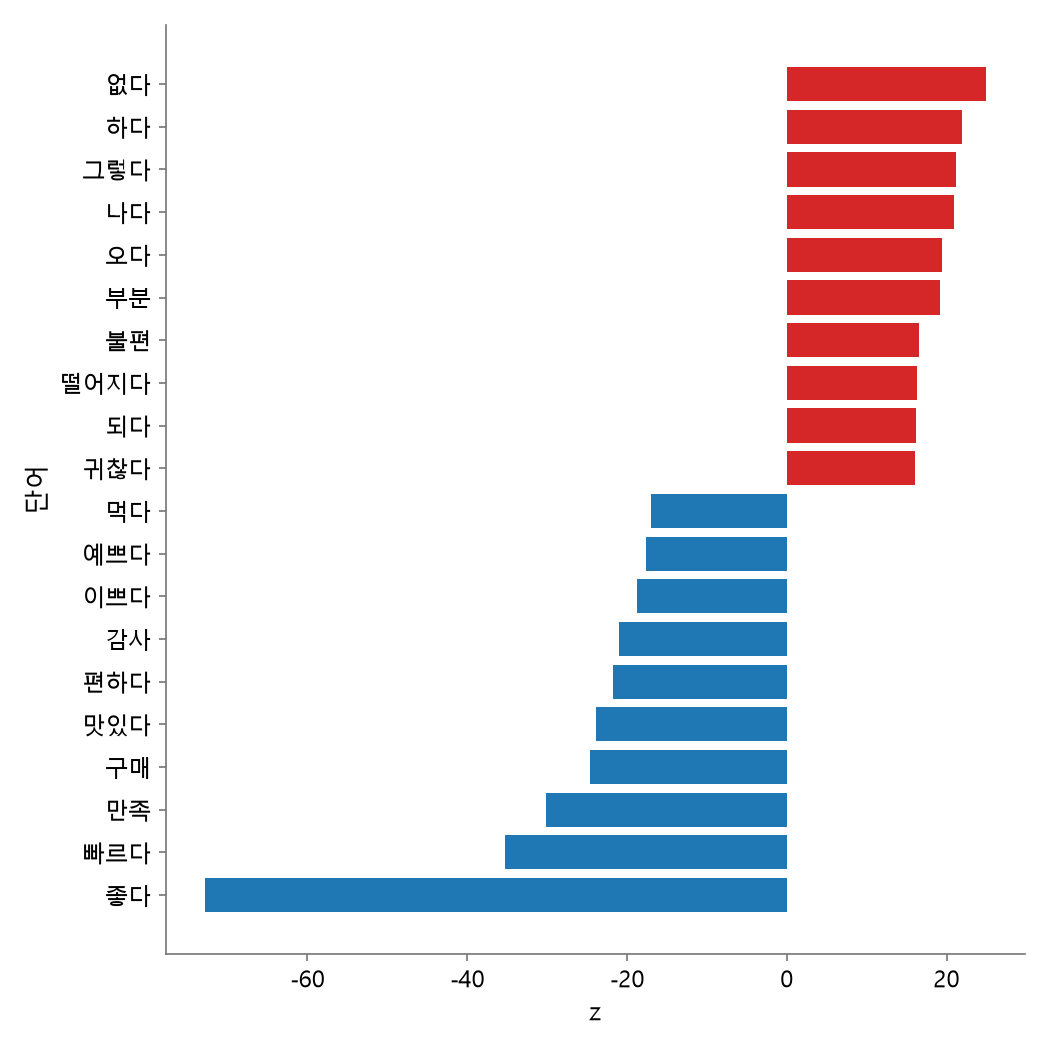

In [ ]:
# 미션 1 — 프롬프트   # ai: prompt
# PROMPT 를 쓰고 → AI 튜터에 "위 PROMPT 대로 코드를 써 줘" → 「이 셀에 넣기」 → ▶
# 시킬 일은 AI 튜터 대화창이 아니라 아래 PROMPT 따옴표 안에 적습니다. 따옴표 안이 비어 있으면 채점과 완성본 풀이가 잠깁니다
PROMPT = """
이 미션의 질문: 리뷰 4만 건에서 별점 1·2점 리뷰가 4·5점 리뷰보다 더 쓰는 단어는 무엇일까요?
# 미션 1 · 준비에서 만든 변수와 함수는 수정하거나 추가하지 말고 그대로 사용해줘

1. 겹친 단어 수 / 개, 정수 (두 별점 그룹마다 문서 비율 상위 15를 골라 두 목록에 모두 있는 단어)
2. 낮은 별점 쪽 1위 단어: z가 가장 큰 단어 '낮은 별점 쪽 1위 =[단어]'
3. 그래프
가로축: z
세로축: 단어
z 상위 10과 하위 10의 가로 막대 20개


"""
# --- 여기부터 AI 코드 ---
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

T = TERMS40 if isinstance(TERMS40, (pd.DataFrame, pd.Series)) else pd.Series(list(TERMS40))
mask = pd.Series(LOW40).to_numpy().astype(bool)
lo = T[mask]    # 별점 1·2점 쪽
hi = T[~mask]   # 별점 4·5점 쪽

def doc_ratio(g):
    # 숫자 행렬(문서×단어)이면 0보다 큰 문서 수를 센다
    if isinstance(g, pd.DataFrame) and all(pd.api.types.is_numeric_dtype(t) for t in g.dtypes):
        return (g > 0).sum() / len(g)
    # 문서마다 단어 목록(또는 공백으로 이은 문자열)이면 문서당 한 번만 센다
    c = Counter()
    for d in g:
        c.update(set(d.split() if isinstance(d, str) else d))
    return pd.Series(c) / len(g)

lo_ratio = doc_ratio(lo)
hi_ratio = doc_ratio(hi)
overlap = set(lo_ratio.nlargest(15).index) & set(hi_ratio.nlargest(15).index)
print(f"겹친 단어 수 = {len(overlap)}")

# 로그 오즈 z (첫 인자: 별점 1·2점 쪽)
res = wlo(lo, hi, alpha0=1000)
if isinstance(res, pd.DataFrame):
    # 단어가 index가 아니라 열에 있으면 그 열을 index로 올린다
    if not all(isinstance(w, str) for w in res.index[:5]):
        res = res.set_index(res.select_dtypes("object").columns[0])
    z = res["z"]
else:
    z = res
z = z.sort_values(ascending=False)
print(f"낮은 별점 쪽 1위 = {z.index[0]}")

# z 상위 10 + 하위 10 가로 막대
top = pd.concat([z.head(10), z.tail(10)]).iloc[::-1]
colors = ["tab:red" if v > 0 else "tab:blue" for v in top]
plt.figure(figsize=(7, 7))
plt.barh(top.index.astype(str), top.values, color=colors)
plt.xlabel("z")
plt.ylabel("단어")
plt.tight_layout()
plt.show()

In [7]:
# 미션 2 · 준비 — 읽고 실행만 합니다. 이 셀이 미션 2 에 쓸 이름을 직접 만듭니다
#  민원 원자료를 과정 복제본에서 한 번 받아 두고(67.9MB), 무작위 2만 건 제목을 명사 집합으로 나눕니다. 10초 안팎 걸립니다
import os, re, time, math, hashlib, urllib.request
from decimal import Decimal, ROUND_HALF_UP
import numpy as np
import pandas as pd
from kiwipiepy import Kiwi
import matplotlib.pyplot as plt

COL = {"남색": "#051C2C", "파랑": "#2251FF", "하늘색": "#00A9F4",   # 맨 위 셀과 같은 색 · 캔버스 폭 —
       "회색": "#757575", "연회색": "#B3B3B3"}                        #  이 셀만 실행해도 정해집니다
FIG_W = 10.0

# 원자료 — 원 출처 URL · 파일 이름 · SHA-256(2026-09-24 확인) · 데이터 페이지
RAW_FILES = {
    "complaints": ("https://www.data.go.kr/cmm/cmm/fileDownload.do?"
                   "atchFileId=FILE_000000002610054&fileDetailSn=1&insertDataPrcus=N",
                   "kftc_complaints_1.csv",
                   "50c098fea2ec1d05191d07c45cd0f75b4d0ac3b5e5ac36910fe40f2aab699ebe",
                   "https://www.data.go.kr/data/15098314/fileData.do"),
}
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"   # 과정 복제본 — 원 출처와 같은 바이트, 먼저 받는 곳


def data_dir():
    # 자료 폴더: 환경변수 NLP_DATA_DIR 이 있으면 그 폴더, 없으면 ./nlp_data
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    # 자료 폴더 → cache/ → raw/ 순서로 찾아 처음 나온 경로, 없으면 None
    for sub in ("", "cache", "raw"):
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _download(url, path, retries=3):
    # url 을 path.part 로 받아 두고 성공하면 True — 실패하면 세 번까지 다시 시도
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    for i in range(retries):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            return True
        except Exception as e:
            print(f"받기 실패 {i + 1}/{retries}: {e}")
            time.sleep(2 * (i + 1))
    return False


def _fetch(url, name, sha=None, strict=False):
    # 로컬에 있으면 그 경로, 없으면 url 에서 받아 SHA-256 확인 뒤 자료 폴더/cache/ 에 두고 경로를 반환함(받지 못하면 None)
    path = find_local(name)
    if path is None:
        path = os.path.join(data_dir(), "cache", name)
        if not _download(url, path):
            return None
        if strict and sha and sha256_of(path + ".part") != sha:
            os.remove(path + ".part")
            raise RuntimeError(f"받은 {name} 의 SHA-256 이 맞지 않습니다. 다시 실행해 보세요.")
        os.replace(path + ".part", path)
    return path


def fetch_raw(name):
    # 원자료 경로: 로컬을 먼저 보고, 없으면 과정 복제본(MIRROR_URL) → 원 출처 URL 순서로 받음
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = _fetch(f"{MIRROR_URL}/{fname}", fname)
        if path is not None and sha256_of(path) != sha:  # 복제본이 다르면 버리고 원 출처로
            os.remove(path)
            path = None
    if path is None:
        path = _fetch(url, fname)
    if path is None:
        raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 교안과 다를 수 있습니다(데이터 페이지: {page})")
    return path


def rnd(x, digits):
    # 십진 값 기준 반올림(끝자리 5 는 올림) — 교안의 수와 같은 방식
    return float(Decimal(f"{float(x):.12g}").quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))


# 민원 파일 읽기 — 문서 비율을 배울 때와 같은 전처리: 시험 입력·빈 제목 행을 빼고, 전화번호 형태를 가린다
TEST_INPUT_RE = re.compile(
    r"(?i)^\s*(?:test|테스트)\s*(?:입니다)?\s*\.?\s*$"
    r"|IN-TEST"
    r"|(?:인바운드|아웃바운드|녹취|수화기).*테스트|테스트.*(?:인바운드|아웃바운드|녹취|수화기)"
    r"|^\s*자동차\s*(?:상담\s*)?테스트"
    r"|^\s*\d{8}\s*[-_ ].*테스트"
    r"|테스트\s*데이터|상담\s*(?:전화\s*)?테스트|전화\s*테스트|헬프데스크\s*시험|^\s*일반\s*테스트")
EMPTY_TITLE_RE = re.compile(r"^[^가-힣A-Za-z]*$")   # 한글 음절도 로마자도 없는 제목(「-」「.」「0」「ㅇ」)
PHONE_RE = re.compile(r"(?<!\d)(?:01[016789]|0\d{1,2})[-.)\s]{0,2}\d{3,4}[-.\s]\d{4}(?!\d)")


def read_complaints(path, verbose=True):
    # 민원 파일(cp949) 읽기 → 열 이름에서 괄호 안 영문을 떼고, 시험 입력·빈 제목 행을 빼고, 전화번호 형태를 가린다
    raw = pd.read_csv(path, encoding="cp949", dtype=str)
    df = raw.rename(columns=lambda c: c.split("(")[0].strip())
    df.insert(0, "row_id", range(len(df)))          # 원자료의 행 번호(0부터)
    title = df["사건제목"].fillna("").str.strip()
    is_test = title.str.contains(TEST_INPUT_RE)
    is_empty = title.str.match(EMPTY_TITLE_RE) & ~is_test
    df = df[~is_test & ~is_empty].copy()
    title = title[df.index]
    df["사건제목"] = title.map(lambda t: PHONE_RE.sub("[전화번호]", t))
    n_masked = int(df["사건제목"].ne(title).sum())
    df = df.reset_index(drop=True)
    if verbose:
        print(f"민원 원본 {len(raw):,}행 → 시험 입력 {int(is_test.sum())}행·빈 제목 {int(is_empty.sum())}행 제거"
              f" → {len(df):,}행, 전화번호 형태 가림 {n_masked}행")
    return df


def sample_rows(df, n, seed=0):
    # 고정 표본: 같은 입력과 같은 seed 면 같은 행이 같은 순서로 나온다
    return df.sample(n=n, random_state=seed)


def kiwi_nouns(texts, kiwi):
    # 문서마다 명사(NNG·NNP) 집합 — 한 제목에 두 번 나온 명사도 한 번만 들어간다(문서 단위)
    return [{t.form for t in toks if t.tag in ("NNG", "NNP")} for toks in kiwi.tokenize(list(texts))]


def wlo(sets_a, sets_b, alpha0=1000.0, min_df=5):
    """가중 로그 오즈(문서 단위) — 이론 「3. 가중 로그 오즈」의 식. z > 0 이면 a 쪽, z < 0 이면 b 쪽 특징 단어
    열: w 단어 · ya/yb 두 집단에서 그 단어를 쓴 문서 수 · a_w 사전 문서 수 · delta 로그 오즈 차이 · var 분산 · z · raw 보정 없는 로그 오즈(+0.5)"""
    ca = pd.Series([w for s in sets_a for w in set(s)]).value_counts()      # 단어마다 그 단어를 쓴 문서 수
    cb = pd.Series([w for s in sets_b for w in set(s)]).value_counts()
    t = pd.DataFrame({"ya": ca, "yb": cb}).fillna(0).astype(int).rename_axis("w").reset_index()
    t = t[t.ya + t.yb >= min_df].sort_values("w").reset_index(drop=True)      # 어휘: 두 집단 합쳐 문서 min_df 건 이상
    na, nb, tot = len(sets_a), len(sets_b), t.ya + t.yb
    t["a_w"] = alpha0 * tot / tot.sum()                                        # 두 집단 문서 합에 비례하는 사전 문서 수
    t["delta"] = (np.log((t.ya + t.a_w) / (na + alpha0 - t.ya - t.a_w))
                  - np.log((t.yb + t.a_w) / (nb + alpha0 - t.yb - t.a_w)))
    t["var"] = 1 / (t.ya + t.a_w) + 1 / (t.yb + t.a_w)
    t["z"] = t.delta / np.sqrt(t["var"])
    t["raw"] = np.log((t.ya + .5) / (na - t.ya + .5)) - np.log((t.yb + .5) / (nb - t.yb + .5))
    return t


AGE20 = ["20 - 29세"]
AGE60P = ["60 - 64세", "65 - 69세", "70 - 79세", "80세이상"]

COMPLAINTS_PATH = fetch_raw("complaints")
C20 = sample_rows(read_complaints(COMPLAINTS_PATH), 20000, seed=0)[["row_id", "연령대명", "성별", "품목명", "사건제목"]]   # 쓸 변수 — 민원 2만 건
import os
os.environ.setdefault("KIWI_ARCH_TYPE", "balanced")  # CPU 종류(Mac·Colab)와 상관없이 형태소 분석 결과를 같게
KIWI = Kiwi(num_workers=2)
NOUNS20 = pd.Series(kiwi_nouns(C20["사건제목"], KIWI), index=C20.index)   # 쓸 변수 — 제목마다 명사 집합
IS20 = C20["연령대명"].isin(AGE20).to_numpy()                             # 쓸 변수 — 20대면 True
IS60P = C20["연령대명"].isin(AGE60P).to_numpy()                           # 쓸 변수 — 60대 이상이면 True

print(f"민원 2만 건 준비 — 20대 {int(IS20.sum()):,}건 · 60대 이상 {int(IS60P.sum()):,}건"
      f" · 제목 한 건의 명사 집합 평균 {NOUNS20.map(len).mean():.1f}개")
print("쓸 수 있는 이름 : C20 · NOUNS20 · IS20 · IS60P · wlo · rnd · KIWI · COL · FIG_W")

민원 원본 499,999행 → 시험 입력 91행·빈 제목 64행 제거 → 499,844행, 전화번호 형태 가림 10행
민원 2만 건 준비 — 20대 2,175건 · 60대 이상 2,446건 · 제목 한 건의 명사 집합 평균 6.0개
쓸 수 있는 이름 : C20 · NOUNS20 · IS20 · IS60P · wlo · rnd · KIWI · COL · FIG_W


선납진료비 · 20대 11건 · 60대 이상 0건 · 로그 오즈 3.26
수강 · 20대 9건 · 60대 이상 0건 · 로그 오즈 3.07
스터디 · 20대 9건 · 60대 이상 0건 · 로그 오즈 3.07
수업 · 20대 8건 · 60대 이상 0건 · 로그 오즈 2.95
카페 · 20대 8건 · 60대 이상 0건 · 로그 오즈 2.95
독서실 · 20대 8건 · 60대 이상 0건 · 로그 오즈 2.95
케이스 · 20대 7건 · 60대 이상 0건 · 로그 오즈 2.83
필라테스 · 20대 35건 · 60대 이상 2건 · 로그 오즈 2.79
헬스장 · 20대 99건 · 60대 이상 7건 · 로그 오즈 2.75
학원 · 20대 45건 · 60대 이상 3건 · 로그 오즈 2.70
1위 단어 = 선납진료비
상위 10 중 합친 문서 30건 미만 = 7 개
판단 : 20대 민원의 특징은 수강·스터디·수업·카페·독서실, 학원·스터디 공간 민원이 20대의 핵심 불만


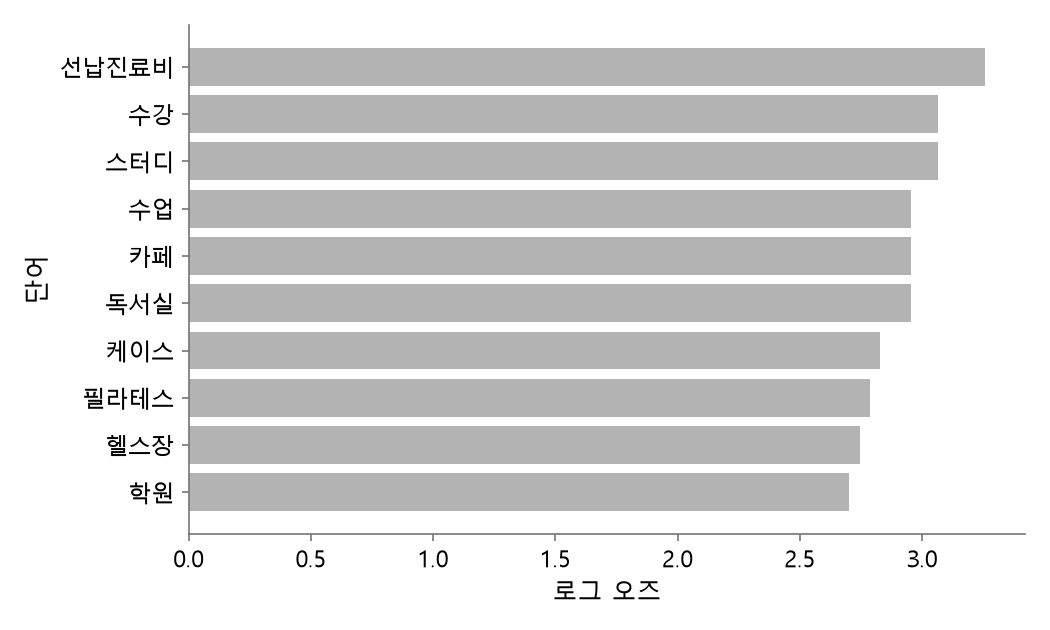

In [8]:
# 미션 2 — 프롬프트 (함정)   # ai: prompt
# 이 미션은 함정입니다. AI 코드 표시선 아래는 전임 담당자가 남긴 코드라 오류 없이 실행되지만 이 표로는 20대 특징 단어를 고를 수 없습니다
# 고칠 지시는 AI 튜터 대화창이 아니라 아래 PROMPT 따옴표 안에 적습니다. 비어 있어도 전임 코드의 채점은 나오지만 완성본 풀이는 잠깁니다
PROMPT = """

"""
# --- 여기부터 AI 코드 ---
# ↓ 전임 담당자의 코드 — 「20대 민원의 핵심 불만은 학원·스터디 공간」이라는 판단의 근거가 된 표. 그대로 실행하면 채점이 ❌ 를 냅니다
df = wlo([s for s, m in zip(NOUNS20, IS20) if m], [s for s, m in zip(NOUNS20, IS60P) if m], alpha0=1000)
top = df.sort_values("raw", ascending=False).head(10)            # 20대 쪽 로그 오즈 상위 10
for w, ya, yb, raw in zip(top.w, top.ya, top.yb, top.raw):
    print(f"{w} · 20대 {ya}건 · 60대 이상 {yb}건 · 로그 오즈 {raw:.2f}")
n30 = int(((top.ya + top.yb) < 30).sum())                         # 두 집단 합쳐 문서 30건 미만인 단어
print("1위 단어 =", top.w.iloc[0])
print("상위 10 중 합친 문서 30건 미만 =", n30, "개")
print("판단 : 20대 민원의 특징은 수강·스터디·수업·카페·독서실, 학원·스터디 공간 민원이 20대의 핵심 불만")

fig, ax = plt.subplots(figsize=(FIG_W * 0.7, 4.2))
ax.barh(top.w[::-1], top.raw[::-1], color=COL["연회색"])
ax.set_xlabel("로그 오즈")
ax.set_ylabel("단어")
plt.show()

환불 · 20대 612건 · 60대 이상 265건 · z 14.12
헬스장 · 20대 99건 · 60대 이상 7건 · z 7.43
취소 · 20대 256건 · 60대 이상 155건 · z 5.98
예약 · 20대 58건 · 60대 이상 11건 · z 5.30
중도 · 20대 91건 · 60대 이상 35건 · z 5.18
학원 · 20대 45건 · 60대 이상 3건 · z 4.97
철회 · 20대 73건 · 60대 이상 27건 · z 4.73
필라테스 · 20대 35건 · 60대 이상 2건 · z 4.36
규정 · 20대 58건 · 60대 이상 20건 · z 4.36
거절 · 20대 54건 · 60대 이상 21건 · z 3.93
1위 단어 = 환불
상위 10 중 합친 문서 30건 미만 = 0 개


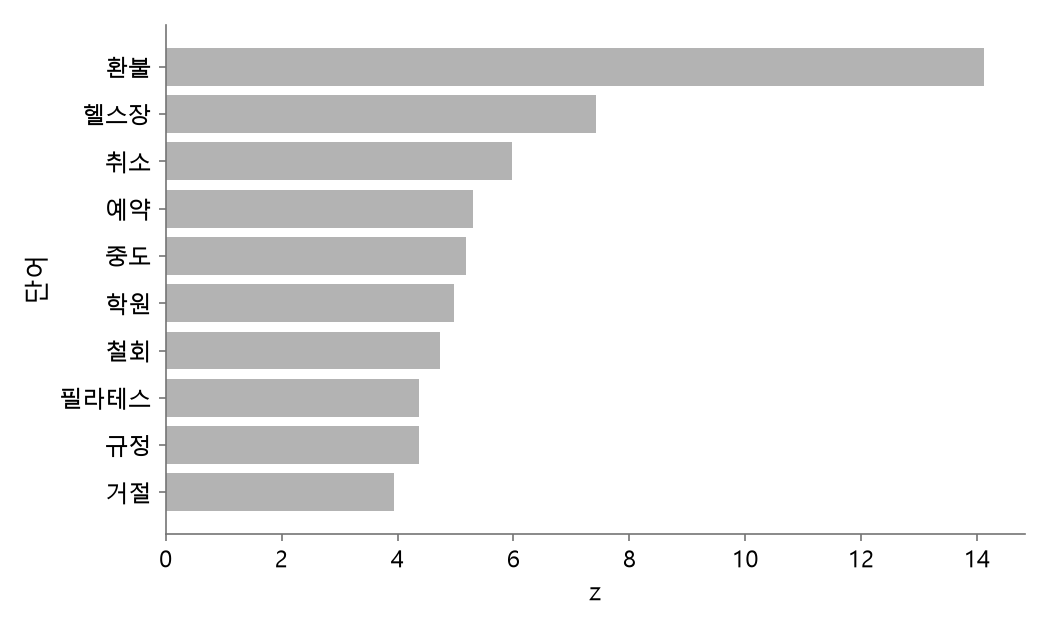

In [9]:
# 미션 2 — 프롬프트 (함정)   # ai: prompt
# 이 미션은 함정입니다. AI 코드 표시선 아래는 전임 담당자가 남긴 코드라 오류 없이 실행되지만 이 표로는 20대 특징 단어를 고를 수 없습니다
# 고칠 지시는 AI 튜터 대화창이 아니라 아래 PROMPT 따옴표 안에 적습니다. 비어 있어도 전임 코드의 채점은 나오지만 완성본 풀이는 잠깁니다
PROMPT = """
아래 전임자 코드를 수정해야해
이걸 sort하는게 잘못된거 같아 ascending=False을 True로 바꾸어야해

1. 상위 10 중 합친 문서 30건 미만 / 단위 개, 정수
2. 1위 단어 / 단어
3 그래프
가로축: z
세로축 이름: 단어
"""
# --- 여기부터 AI 코드 ---
df = wlo([s for s, m in zip(NOUNS20, IS20) if m], [s for s, m in zip(NOUNS20, IS60P) if m], alpha0=1000)
top = df.sort_values("z", ascending=False).head(10)               # 20대 쪽 z 상위 10
for w, ya, yb, z in zip(top.w, top.ya, top.yb, top.z):
    print(f"{w} · 20대 {ya}건 · 60대 이상 {yb}건 · z {z:.2f}")
n30 = int(((top.ya + top.yb) < 30).sum())                         # 두 집단 합쳐 문서 30건 미만인 단어
print("1위 단어 =", top.w.iloc[0])
print("상위 10 중 합친 문서 30건 미만 =", n30, "개")

fig, ax = plt.subplots(figsize=(FIG_W * 0.7, 4.2))
ax.barh(top.w[::-1], top.z[::-1], color=COL["연회색"])
ax.set_xlabel("z")
ax.set_ylabel("단어")
plt.show()